# Addis Ababa City Road Traffic Accident Severity Dataset

This dataset contains traffic accident records from Addis Ababa City, Ethiopia, spanning the years 2016 to 2022. The dataset includes 13,064 rows and 31 features related to various factors influencing road traffic accident severity. The target variable is categorized into three severity levels: slight, serious, and fatal injuries.

### Dataset Description

This project uses a road traffic accident dataset collected by the **Addis Ababa Police Department**. The dataset contains information about road accidents, including **weather conditions, collision type, driver characteristics, road conditions, and accident time**.

The main objective is to **analyze the factors associated with accident severity and predict accident severity using machine learning algorithms**. The results can support **traffic safety research, urban planning, and road safety policy development**.

**Key features in the dataset include:**

Accident Severity (Target Variable): Categorical variable indicating the severity of the accident (slight, serious, fatal).
Weather Conditions: Describes the weather at the time of the accident (e.g., clear, rainy, foggy).
Collision Type: The type of collision (e.g., rear-end, side-impact).
Driver Demographics: Features like driver age, driver sex, and experience that may affect accident outcomes.
Location: Various aspects of the accident location, including junction type, road type, and alignment.
Temporal Features: Time-related variables such as day of the week, time of day, and seasonal trends.
Vehicle Information: Includes vehicle type, vehicle defect, vehicle movement, and the relationship between the vehicle owner and the driver.
Casualty Information: Includes age, sex, and fitness of the casualty.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


Step 1: Cleaning

In [4]:
df = pd.read_csv('Addis_Ababa_city_RTA.csv')

# 1. Check shape, dtypes, missing values
df.info()
df.isnull().sum()

# 2. Check duplicates
df.duplicated().sum()

<class 'pandas.DataFrame'>
RangeIndex: 13063 entries, 0 to 13062
Data columns (total 31 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   Time                         13063 non-null  str  
 1   Day_of_week                  13063 non-null  str  
 2   Age_band_of_driver           13063 non-null  str  
 3   Drivers_gender               13063 non-null  str  
 4   Educational_level            12297 non-null  str  
 5   Vehicle_driver_relation      12464 non-null  str  
 6   Driving_experience           12187 non-null  str  
 7   Type_of_vehicle              12096 non-null  str  
 8   Owner_of_vehicle             12555 non-null  str  
 9   Service_year_of_vehicle      9073 non-null   str  
 10  Defect_of_vehicle            8496 non-null   str  
 11  Area_accident_occured        12823 non-null  str  
 12  Lanes_or_Medians             12586 non-null  str  
 13  Road_allignment              12919 non-null  str  
 14  T

np.int64(0)

In [5]:
# Heavy-missing columns -> fill with "Unknown"
heavy_missing_cols = ['Defect_of_vehicle', 'Service_year_of_vehicle',
                       'Work_of_casuality', 'Fitness_of_casuality']
df[heavy_missing_cols] = df[heavy_missing_cols].fillna('Unknown')

# Lighter-missing categorical columns -> fill with mode
light_missing_cols = ['Educational_level', 'Vehicle_driver_relation', 'Driving_experience',
                       'Type_of_vehicle', 'Owner_of_vehicle', 'Area_accident_occured',
                       'Lanes_or_Medians', 'Road_allignment', 'Type_of_collision',
                       'Vehicle_movement']
for col in light_missing_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

# Confirm no missing values remain
df.isnull().sum().sum()

np.int64(0)

In [6]:
df['Hour'] = pd.to_datetime(df['Time'], format='%H:%M:%S').dt.hour

In [7]:
df.isnull().sum().sum()


np.int64(0)

In [8]:
df['Hour']
df['Hour'].min()


np.int32(0)

In [9]:
df['Hour'].max()

np.int32(23)

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df.to_csv('Addis_Ababa_city_RTA_cleaned.csv', index=False)

Exploratory Data Analysis

The dataset was explored to identify patterns in accident occurrence and severity. The analysis focuses on accident severity, time of day, day of the week, weather conditions, casualty numbers, and light conditions.

Step 2: Visualization (matplotlib + seaborn).

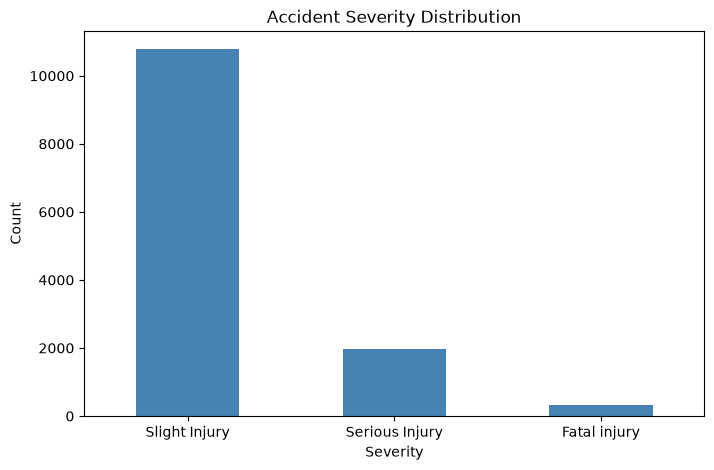

In [12]:
# 1. Target distribution
plt.figure(figsize=(8,5))
df['Accident_severity'].value_counts().plot(kind='bar', color='steelblue')
plt.title('Accident Severity Distribution')
plt.xlabel('Severity')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.show()

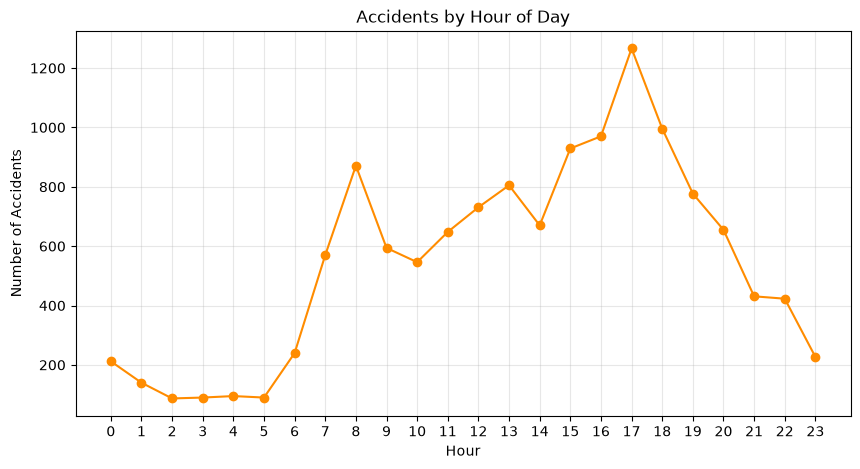

In [13]:
plt.figure(figsize=(10,5))
df.groupby('Hour').size().plot(kind='line', marker='o', color='darkorange')
plt.title('Accidents by Hour of Day')
plt.xlabel('Hour')
plt.ylabel('Number of Accidents')
plt.xticks(range(0,24))
plt.grid(alpha=0.3)
plt.show()

C:\Users\hp\AppData\Local\Temp\ipykernel_23360\1472174001.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Day_of_week',


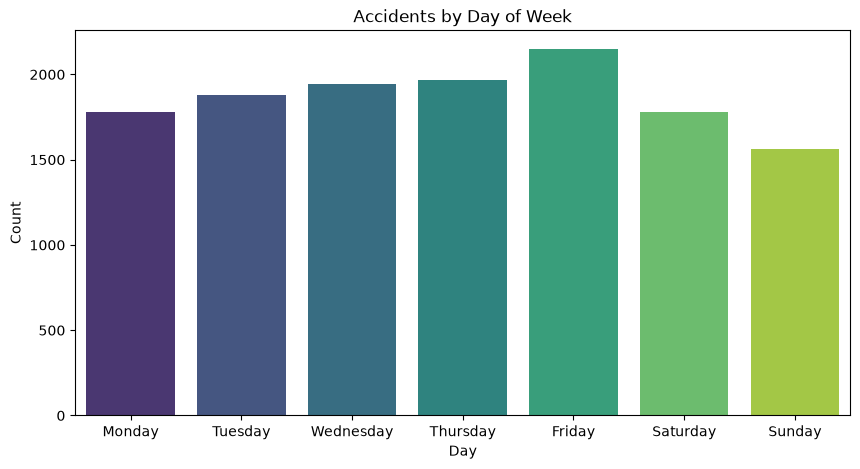

In [14]:
plt.figure(figsize=(10,5))
sns.countplot(data=df, x='Day_of_week', 
              order=['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday'],
              palette='viridis')
plt.title('Accidents by Day of Week')
plt.xlabel('Day')
plt.ylabel('Count')
plt.show()

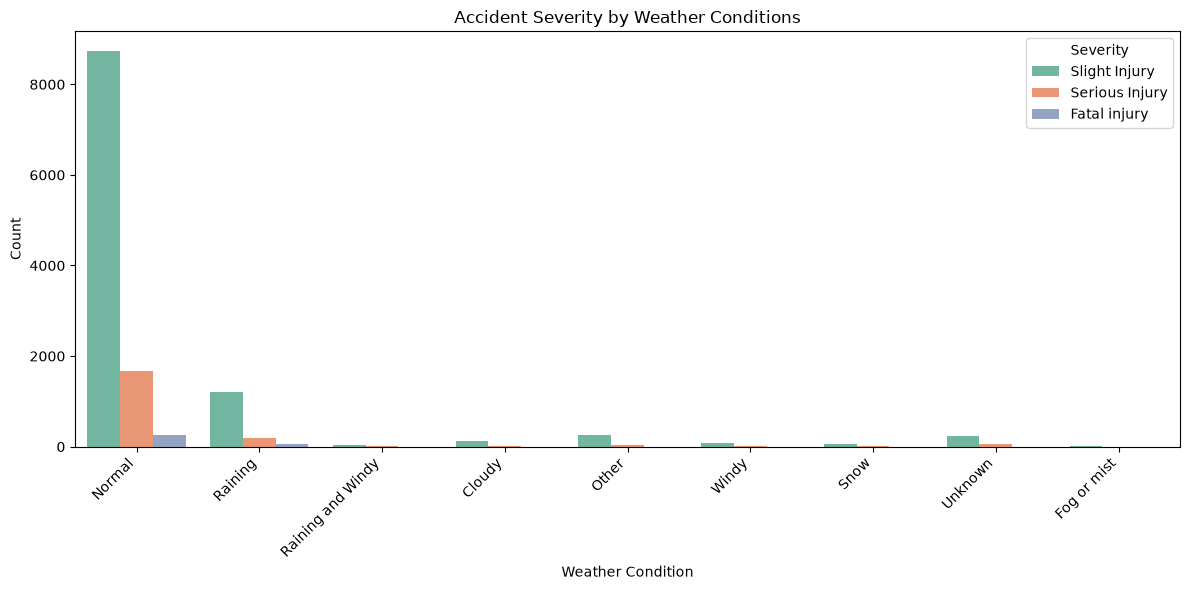

In [15]:
plt.figure(figsize=(12,6))
sns.countplot(data=df, x='Weather_conditions', hue='Accident_severity', palette='Set2')
plt.title('Accident Severity by Weather Conditions')
plt.xlabel('Weather Condition')
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Severity')
plt.tight_layout()
plt.show()

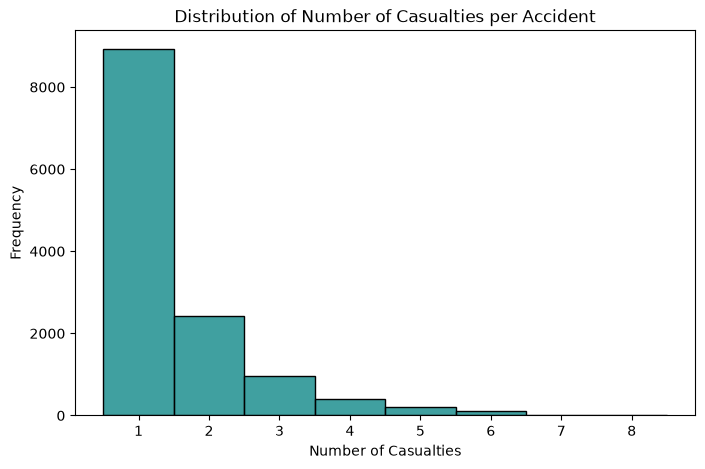

In [16]:
plt.figure(figsize=(8,5))
sns.histplot(data=df, x='Number_of_casualties', bins=range(1, df['Number_of_casualties'].max()+2), 
             discrete=True, color='teal')
plt.title('Distribution of Number of Casualties per Accident')
plt.xlabel('Number of Casualties')
plt.ylabel('Frequency')
plt.show()

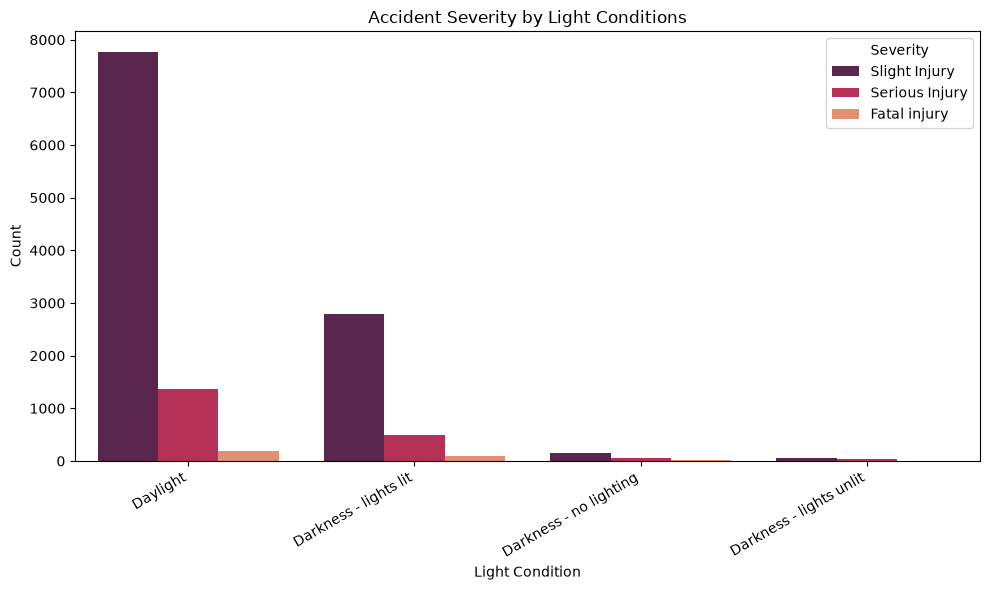

In [17]:
plt.figure(figsize=(10,6))
sns.countplot(data=df, x='Light_conditions', hue='Accident_severity', palette='rocket')
plt.title('Accident Severity by Light Conditions')
plt.xlabel('Light Condition')
plt.ylabel('Count')
plt.xticks(rotation=30, ha='right')
plt.legend(title='Severity')
plt.tight_layout()
plt.show()

In [18]:
from sklearn.preprocessing import LabelEncoder

df_encoded = df.copy()
le = LabelEncoder()
for col in df_encoded.select_dtypes(include='object').columns:
    df_encoded[col] = le.fit_transform(df_encoded[col].astype(str))

C:\Users\hp\AppData\Local\Temp\ipykernel_23360\400359553.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df_encoded.select_dtypes(include='object').columns:


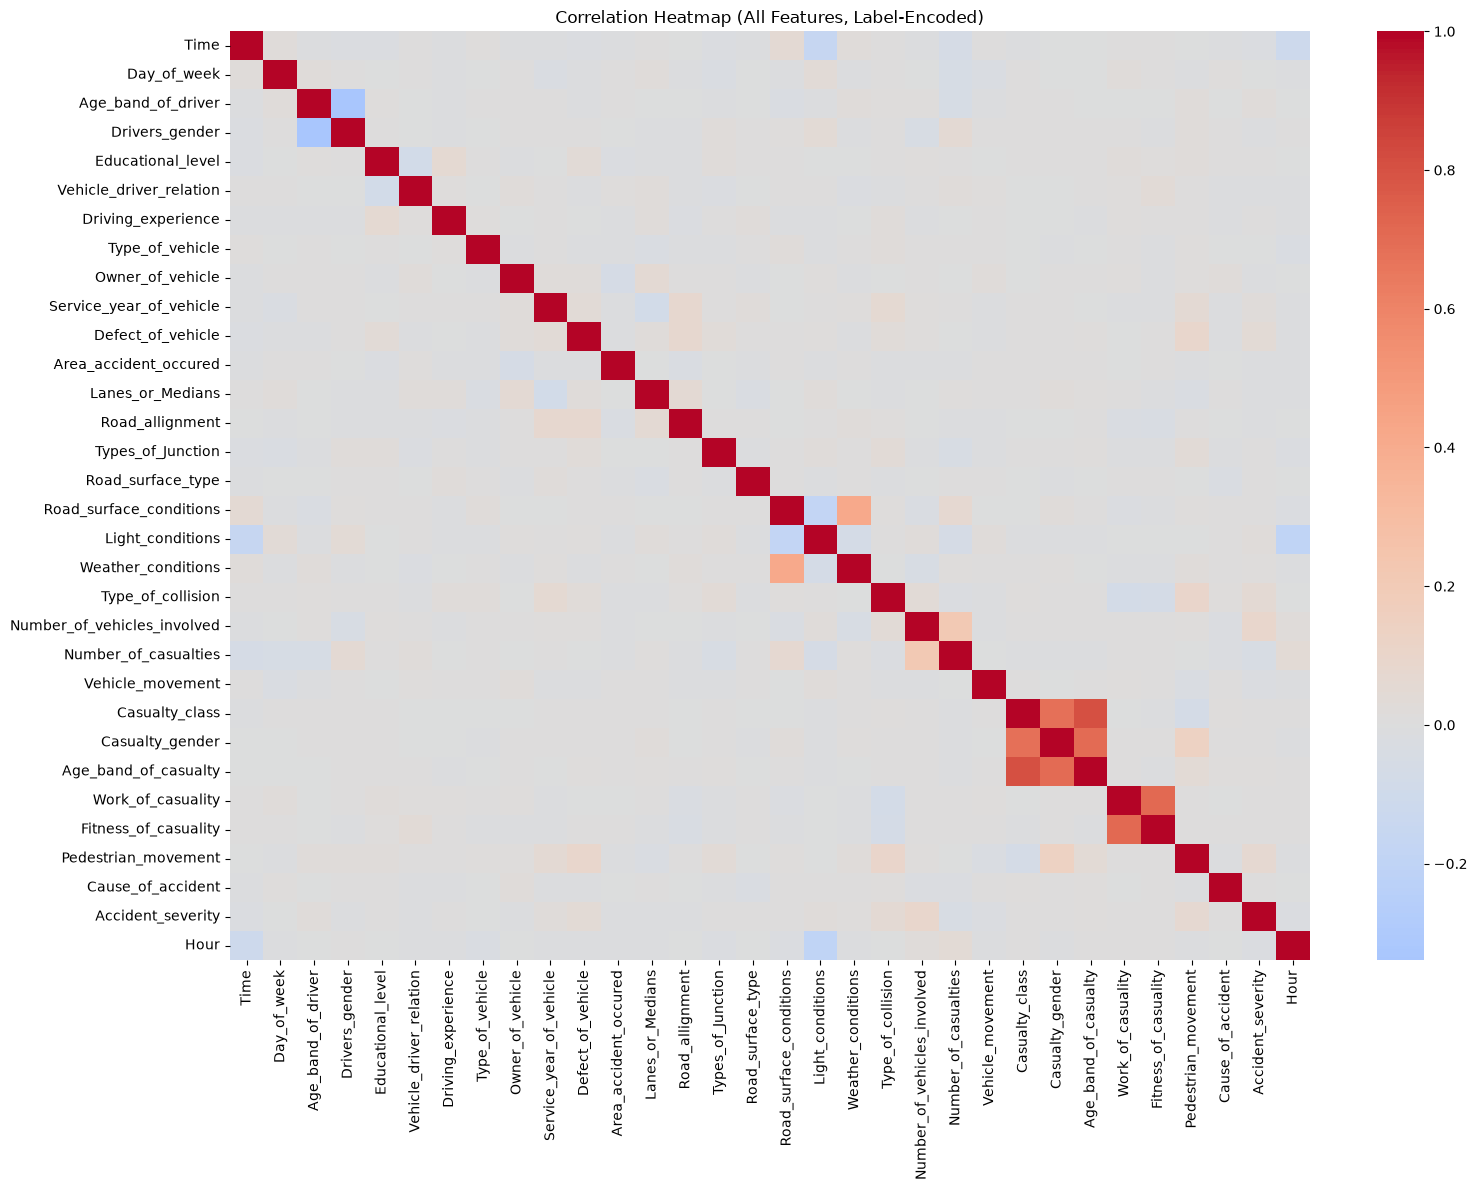

In [19]:
plt.figure(figsize=(16,12))
sns.heatmap(df_encoded.corr(), cmap='coolwarm', center=0, annot=False)
plt.title('Correlation Heatmap (All Features, Label-Encoded)')
plt.tight_layout()
plt.show()

Step 3: ML Prediction

In [20]:
X = df_encoded.drop('Accident_severity', axis=1)
y = df_encoded['Accident_severity']

In [21]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [22]:
X_train.shape, X_test.shape

((10450, 31), (2613, 31))

In [23]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(max_depth=10, random_state=42)
dt_model.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples i

In [24]:
y_pred = dt_model.predict(X_test)

In [25]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Accuracy:", accuracy_score(y_test, y_pred))
print()
print(classification_report(y_test, y_pred))

Accuracy: 0.8166858017604286

              precision    recall  f1-score   support

           0       0.22      0.03      0.06        62
           1       0.40      0.13      0.19       395
           2       0.84      0.97      0.90      2156

    accuracy                           0.82      2613
   macro avg       0.49      0.37      0.38      2613
weighted avg       0.76      0.82      0.77      2613



In [31]:
# Check what LabelEncoder mapped 'Accident_severity' to
from sklearn.preprocessing import LabelEncoder
severity_le = LabelEncoder()
severity_le.fit(df['Accident_severity'])
print(list(zip(
    severity_le.classes_, 
    severity_le.transform(severity_le.classes_)
    )))

[('Fatal injury', np.int64(0)), ('Serious Injury', np.int64(1)), ('Slight Injury', np.int64(2))]


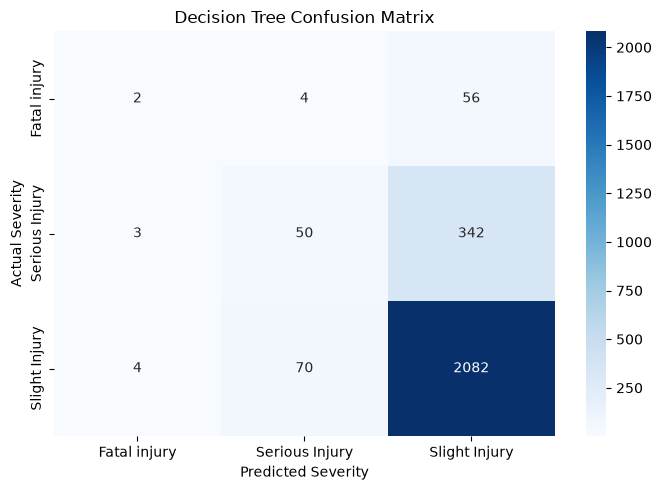

In [32]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=severity_le.classes_,
            yticklabels=severity_le.classes_)

plt.title('Decision Tree Confusion Matrix')
plt.xlabel('Predicted Severity')
plt.ylabel('Actual Severity')
plt.tight_layout()
plt.show()

In [28]:
dt_model_balanced = DecisionTreeClassifier(max_depth=10, class_weight='balanced', random_state=42)
dt_model_balanced.fit(X_train, y_train)

y_pred_balanced = dt_model_balanced.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_balanced))
print()
print(classification_report(y_test, y_pred_balanced))

Accuracy: 0.711825487944891

              precision    recall  f1-score   support

           0       0.12      0.32      0.18        62
           1       0.25      0.26      0.25       395
           2       0.85      0.81      0.83      2156

    accuracy                           0.71      2613
   macro avg       0.41      0.46      0.42      2613
weighted avg       0.74      0.71      0.73      2613



In [29]:
results = pd.DataFrame({
    'Model': ['Decision Tree', 'Balanced Decision Tree'],
    'Accuracy': [0.8167, 0.7118],
    'Macro F1': [0.38, 0.42]
})

results

,Model,Accuracy,Macro F1
0,Decision Tree,0.8167,0.38
1,Balanced Decision Tree,0.7118,0.42


Model Comparison

The standard Decision Tree achieved higher overall accuracy (81.7%), while the balanced Decision Tree achieved a higher macro F1-score (0.42). This indicates that balancing the classes improved the model's ability to recognize minority severity classes, although it reduced overall accuracy.

Which factors are most important for predicting accident severity?

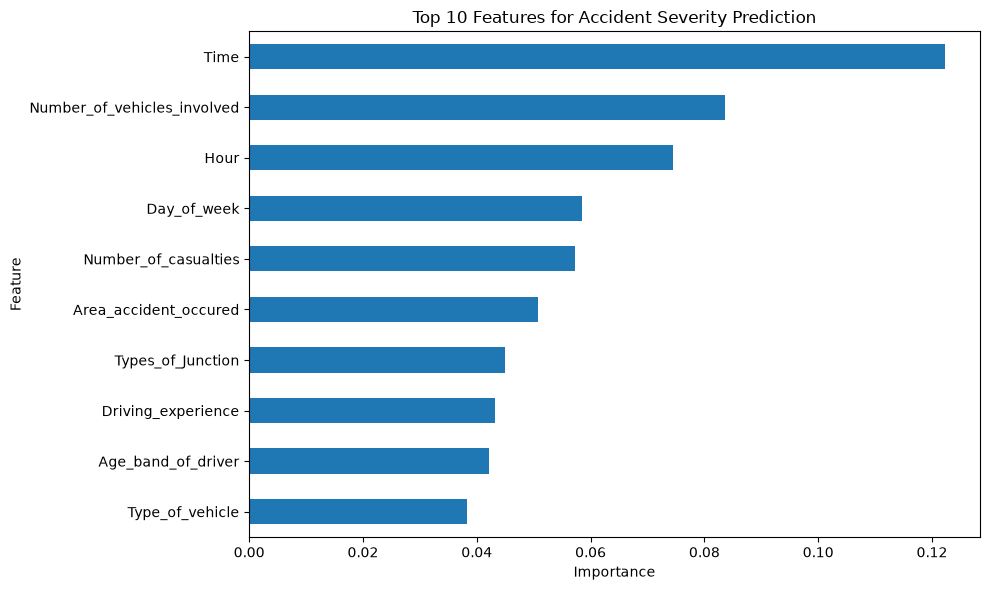

In [30]:
feature_importance = pd.Series(
    dt_model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

plt.figure(figsize=(10,6))
feature_importance.head(10).sort_values().plot(kind='barh')

plt.title('Top 10 Features for Accident Severity Prediction')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

## Conclusion

This project analyzed road traffic accidents in Addis Ababa and investigated factors associated with accident severity. The exploratory analysis examined accident patterns across time, day of the week, weather conditions, casualty numbers, and light conditions.

A Decision Tree classifier was developed to predict accident severity. The standard Decision Tree achieved an accuracy of approximately **81.7%**, while the balanced version achieved approximately **71.2% accuracy** but provided better balance across the severity classes based on macro F1-score.

The results also show that the accident-severity classes are imbalanced, with Slight Injury representing the majority of cases. Therefore, accuracy alone is not sufficient for evaluating the model, and metrics such as precision, recall, and macro F1-score are important, particularly for identifying serious and fatal accidents.

Overall, the analysis demonstrates how data visualization and machine learning can be used to investigate road traffic accident patterns and support traffic-safety research and decision-making.


Thankyou so much!